# 1.11 지도·비지도 학습의 입력과 출력 비교

wine.csv는 178행입니다. scikit-learn 내장 Wine 데이터(load_wine), UCI Wine에서 유래한 178개 관측. 생성 자료 아님. 13개 연속형 화학 분석 특성과 target(0,1,2). 7장은 target==0을 양성으로 재정의한다. 물리 단위는 원 출처 설명을 확인한다.

선정 이유: 동일한 13개 화학 특성과 세 품종 라벨을 갖추어 같은 입력에서 정답 사용 여부만 비교할 수 있기 때문에 Wine 자료를 선택했습니다. 두 모델은 같은 훈련 124행과 테스트 54행을 사용합니다.

커널을 다시 시작한 뒤 각 셀을 위에서 아래로 실행합니다. 코드에는 가져오기와 함수 정의도 포함되어 있습니다.

## 셀 1 라이브러리 가져오기

가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 훈련 평가 분리 함수(Train Test Split)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 처리 단계 연결 함수(Make Pipeline)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 표준화 변환기(Standard Scaler)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 로지스틱 회귀 분류기(Logistic Regression)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 케이평균 군집화(K-Means Clustering)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 정확도(Accuracy) 계산 함수, 조정 랜드 지수(Adjusted Rand Index) 계산 함수를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

In [1]:
# 가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from pathlib import Path

# 가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import json

# 가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import numpy as np

# 가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import pandas as pd

# 가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import matplotlib.pyplot as plt

# 가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from IPython.display import display, Image as NotebookImage

# 가져오기(Import) 문장으로 훈련 평가 분리 함수(Train Test Split)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.model_selection import train_test_split

# 가져오기(Import) 문장으로 처리 단계 연결 함수(Make Pipeline)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.pipeline import make_pipeline

# 가져오기(Import) 문장으로 표준화 변환기(Standard Scaler)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.preprocessing import StandardScaler

# 가져오기(Import) 문장으로 로지스틱 회귀 분류기(Logistic Regression)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.linear_model import LogisticRegression

# 가져오기(Import) 문장으로 케이평균 군집화(K-Means Clustering)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.cluster import KMeans

# 가져오기(Import) 문장으로 정확도(Accuracy) 계산 함수, 조정 랜드 지수(Adjusted Rand Index) 계산 함수를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.metrics import accuracy_score, adjusted_rand_score

## 셀 2 입력·계산·출력 확인

계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.

현재 노트북 또는 프로그램 폴더(Current Directory, HERE)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

장 폴더(Chapter Directory, CHAPTER)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

입력 자료 폴더(Data Directory, DATA)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

결과 저장 폴더(Output Directory, OUT)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

앞 셀의 값을 사용하여 OUT.mkdir(parents=True, exist_ok=True) 동작을 수행합니다. 셀 순서를 바꾸거나 중간 셀을 생략하지 않습니다.

검증 조건(Assertion)이 참인지 확인합니다. 거짓이면 셀을 중단하며 성공한 결과로 기록하지 않습니다.

In [2]:
# 계산 결과의 축·제목·기호·범례를 설정합니다. 표시 방식이 바뀌어도 원본 수치가 바뀌는 것은 아닙니다.
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":11,
    "axes.prop_cycle":plt.cycler(color=["black","0.45","0.7"]),
    "svg.fonttype":"none", "figure.figsize":(7.0,4.2)})

# 현재 노트북 또는 프로그램 폴더(Current Directory, HERE)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
HERE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()

# 장 폴더(Chapter Directory, CHAPTER)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
CHAPTER = HERE if (HERE / "data").exists() else HERE.parent

# 입력 자료 폴더(Data Directory, DATA)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
DATA = CHAPTER / "data"

# 결과 저장 폴더(Output Directory, OUT)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
OUT = HERE / "results" / "sec_11_learning_modes"

# 앞 셀의 값을 사용하여 OUT.mkdir(parents=True, exist_ok=True) 동작을 수행합니다. 셀 순서를 바꾸거나 중간 셀을 생략하지 않습니다.
OUT.mkdir(parents=True, exist_ok=True)

# 검증 조건(Assertion)이 참인지 확인합니다. 거짓이면 셀을 중단하며 성공한 결과로 기록하지 않습니다.
assert DATA.exists(), f"장별 data 폴더가 없습니다: {DATA}. 저장소 전체를 내려받으세요."

## 셀 3 함수와 모듈 정의

현재 계산으로 만든 그림을 SVG와 300dpi PNG로 저장하고 노트북 셀에 표시합니다.

In [3]:
# 현재 계산으로 만든 그림을 SVG와 300dpi PNG로 저장하고 노트북 셀에 표시합니다.
def figure(out, name):
    # 실제 현재 그림을 벡터와 300dpi 흑백 삽입본으로 저장합니다.
    plt.tight_layout()
    plt.savefig(out / (name + ".svg"), facecolor="white")
    plt.savefig(out / (name + ".png"), dpi=300, facecolor="white")
    if "get_ipython" in globals():
        display(NotebookImage(filename=str(out / (name + ".png"))))
    plt.close()

## 셀 4 함수와 모듈 정의

계산한 지표를 JSON 파일과 셀의 문자 출력으로 기록합니다.

In [4]:
# 계산한 지표를 JSON 파일과 셀의 문자 출력으로 기록합니다.
def report(out, name, metrics):
    # 계산된 값만 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.
    text = json.dumps(metrics, ensure_ascii=False, indent=2, allow_nan=False)
    (out / (name + ".json")).write_text(text, encoding="utf-8")
    print(text)

## 셀 5 입력·계산·출력 확인

자료 표(Data Frame, frame)에 CSV 파일을 표로 읽습니다. 열 이름과 목표 열을 다음 출력에서 확인합니다.

입력 특성 행렬(Feature Matrix, X)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

목표 벡터(Target Vector, y)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

훈련·평가 분리(Train Test Split)를 수행합니다. 두 행 번호 배열을 반환하는 경우 앞 배열은 훈련 행, 뒤 배열은 평가 행입니다. 네 배열을 반환하는 경우 입력과 목표의 행 대응을 유지합니다. test_size는 평가 비율이며 stratify는 클래스 비율 유지 조건입니다.

분류기(Classifier, clf)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

이 셀의 훈련 입력으로 모델을 적합합니다. 평가 데이터에 다시 적합하지 않습니다.

예측 결과(Predictions, pred)를 이미 적합한 모델로 계산합니다. 예측할 때 훈련을 다시 수행하지 않습니다.

군집 모델(Clustering Model, cluster)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

이 셀의 훈련 입력으로 모델을 적합합니다. 평가 데이터에 다시 적합하지 않습니다.

변수 groups를 이미 적합한 모델로 계산합니다. 예측할 때 훈련을 다시 수행하지 않습니다.

계산된 평가 지표(Evaluation Metrics, metrics)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

변수 fig·변수 axes를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.

In [5]:
# 자료 표(Data Frame, frame)에 CSV 파일을 표로 읽습니다. 열 이름과 목표 열을 다음 출력에서 확인합니다.
frame = pd.read_csv(DATA / "wine.csv")

# 입력 특성 행렬(Feature Matrix, X)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
X = frame.drop(columns="target")

# 목표 벡터(Target Vector, y)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
y = frame["target"]

# 훈련·평가 분리(Train Test Split)를 수행합니다. 두 행 번호 배열을 반환하는 경우 앞 배열은 훈련 행, 뒤 배열은 평가 행입니다. 네 배열을 반환하는 경우 입력과 목표의 행 대응을 유지합니다. test_size는 평가 비율이며 stratify는 클래스 비율 유지 조건입니다.
train, test = train_test_split(np.arange(len(X)), test_size=.3,
    stratify=y, random_state=42)

# 분류기(Classifier, clf)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

# 이 셀의 훈련 입력으로 모델을 적합합니다. 평가 데이터에 다시 적합하지 않습니다.
clf.fit(X.iloc[train], y.iloc[train])

# 예측 결과(Predictions, pred)를 이미 적합한 모델로 계산합니다. 예측할 때 훈련을 다시 수행하지 않습니다.
pred = clf.predict(X.iloc[test])

# 군집 모델(Clustering Model, cluster)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
cluster = make_pipeline(StandardScaler(), KMeans(n_clusters=3,
    random_state=42, n_init=10))

# 이 셀의 훈련 입력으로 모델을 적합합니다. 평가 데이터에 다시 적합하지 않습니다.
cluster.fit(X.iloc[train])

# 변수 groups를 이미 적합한 모델로 계산합니다. 예측할 때 훈련을 다시 수행하지 않습니다.
groups = cluster.predict(X.iloc[test])

# 계산된 평가 지표(Evaluation Metrics, metrics)를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
metrics = {"test_n":len(test), "accuracy":accuracy_score(y.iloc[test],pred),
    "cluster_ARI":adjusted_rand_score(y.iloc[test],groups)}

# 변수 fig·변수 axes를 오른쪽 식으로 계산하여 다음 단계에서 재사용합니다. 값과 형태(Shape)를 구분합니다.
fig, axes = plt.subplots(1,2,figsize=(7.2,3.5))

## 셀 6 입력·계산·출력 확인

반복 조건 for ax, labels, title in zip(axes,[pred,groups],["Supervised", "Unsupervised"]):에 따라 같은 처리를 수행합니다. 루프 내부의 들여쓰기는 반복마다 실행되며 반복 종료 뒤 변수에는 마지막 계산 상태가 남습니다.

실제 계산한 그림을 저장하고 출력합니다. 가로축·세로축·범례의 의미는 이 실습의 결과 해설에서 확인합니다.

앞 셀의 값을 사용하여 pd.DataFrame({"row":test,"true":y.iloc[test].to_numpy(), 동작을 수행합니다. 셀 순서를 바꾸거나 중간 셀을 생략하지 않습니다.

계산된 값만 결과 파일과 셀 출력에 기록합니다. 이후 비교에는 출력 파일과 데이터 버전을 함께 사용합니다.

{
  "test_n": 54,
  "accuracy": 0.9814814814814815,
  "cluster_ARI": 0.8341623876765083
}


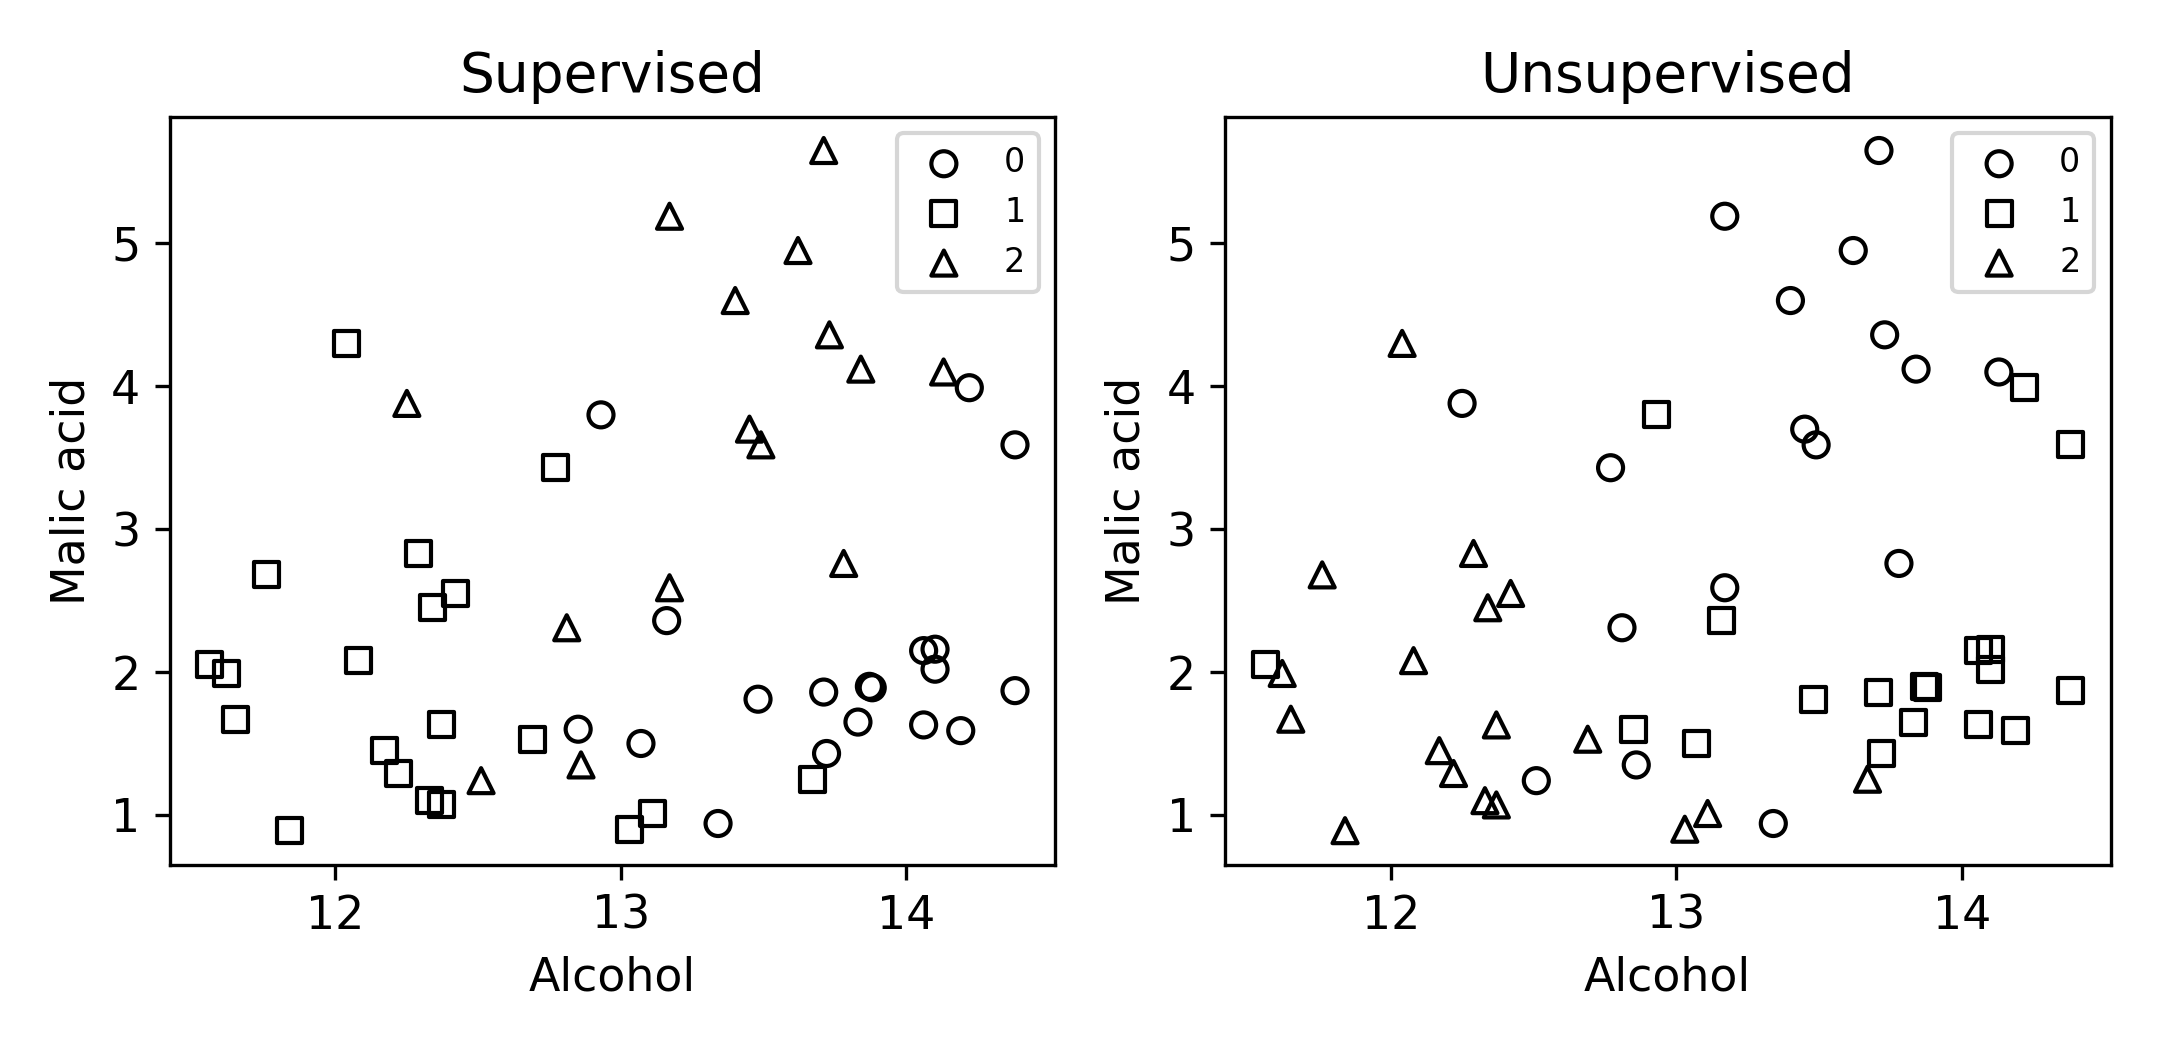

In [6]:
# 반복 조건 for ax, labels, title in zip(axes,[pred,groups],["Supervised", "Unsupervised"]):에 따라 같은 처리를 수행합니다. 루프 내부의 들여쓰기는 반복마다 실행되며 반복 종료 뒤 변수에는 마지막 계산 상태가 남습니다.
for ax, labels, title in zip(axes,[pred,groups],["Supervised", "Unsupervised"]):
    for c, marker in enumerate(["o","s","^"]):
        mask = labels == c
        ax.scatter(X.iloc[test,0][mask],X.iloc[test,1][mask],
            marker=marker,facecolors="none",edgecolors="black",label=str(c))
    ax.set(xlabel="Alcohol",ylabel="Malic acid",title=title)
    ax.legend(fontsize=8)

# 실제 계산한 그림을 저장하고 출력합니다. 가로축·세로축·범례의 의미는 이 실습의 결과 해설에서 확인합니다.
figure(OUT,"learning_modes")

# 앞 셀의 값을 사용하여 pd.DataFrame({"row":test,"true":y.iloc[test].to_numpy(), 동작을 수행합니다. 셀 순서를 바꾸거나 중간 셀을 생략하지 않습니다.
pd.DataFrame({"row":test,"true":y.iloc[test].to_numpy(),
    "pred":pred,"cluster":groups}).to_csv(OUT/"learning_modes.csv",index=False)

# 계산된 값만 결과 파일과 셀 출력에 기록합니다. 이후 비교에는 출력 파일과 데이터 버전을 함께 사용합니다.
report(OUT,"learning_modes",metrics)

## 그림과 결과 해석

왼쪽은 지도학습(Supervised Learning)의 예측 품종이고 오른쪽은 비지도학습(Unsupervised Learning)의 군집 번호입니다. 가로축은 알코올(alcohol), 세로축은 말산(malic acid)이지만 실제 모델은 13개 특성을 사용합니다. 두 그림의 번호 0·1·2가 같은 품종을 뜻하지 않습니다. 분류 결과는 정확도(Accuracy), 군집 관계는 조정 랜드 지수(Adjusted Rand Index, ARI)로 평가합니다. 품종 정답은 군집 훈련에 전달하지 않고 외부 평가에서만 사용합니다. 평면에서 겹쳐도 나머지 11개 입력으로 구분될 수 있습니다.